# Video 5: Tumor versus non tumor comparison

Notes for this notebook.

This notebook generates the visuals for the fifth video in the Multimodal Spatial Biology series. Here we repeat the same pipeline from earlier videos, registration, segmentation, quantification, on the non tumor liver core, and compare it directly against the tumor core from the earlier videos.

All output images are saved into outputs/video5, next to this notebook. That folder is also where the slide deck for this video will be placed.


In [ ]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



import warnings
warnings.filterwarnings("ignore", message="invalid value encountered in divide")


In [8]:
%matplotlib inline

In [2]:
OUTPUT_DIR = Path("outputs/video5")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video5


## Load the dataset

The loader always reads all four cores in the manifest, so we only need one load call to get access to both core01_hcc, the tumor core we have used throughout the series, and core02_non_tumour, the healthy liver core we are introducing in this video. We need everything, H and E, COMET, boundaries, and transcripts, since we are repeating the full pipeline on the new core.


In [3]:
from unumlocalia.io import DatasetLoader

DATA_DIR = Path("data/UnumLocalia")

t0 = time.time()
loader = DatasetLoader(str(DATA_DIR)).load(
    do_load_transcripts=True,
    load_boundaries=True,
    load_he=True,
    load_comet=True,
)
print("Load time in seconds:", round(time.time() - t0, 1))

tumor_id = "core01_hcc"
normal_id = "core02_non_tumour"


Load time in seconds: 26.3


## Morphology side by side

Before looking at any quantification, it helps to simply look at the two tissue types next to each other. Tumor tissue often shows disrupted architecture compared to the more regular structure of healthy liver.


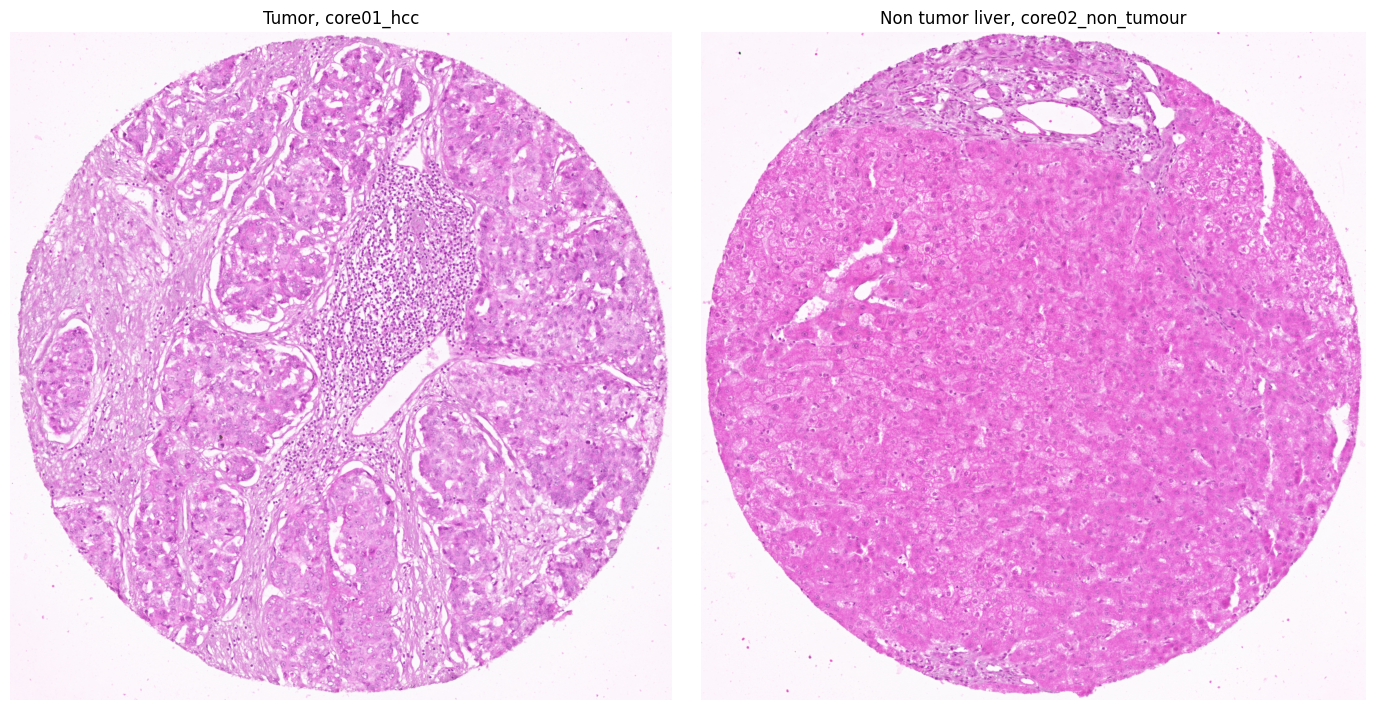

Saved slide_he_tumor_vs_normal.png


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(loader.he_arrays[tumor_id])
axes[0].set_title("Tumor, core01_hcc")
axes[0].axis("off")

axes[1].imshow(loader.he_arrays[normal_id])
axes[1].set_title("Non tumor liver, core02_non_tumour")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_he_tumor_vs_normal.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_he_tumor_vs_normal.png")


## Quantifying the non tumor core

We reuse the same quantify_comet_segmentation function from Video 3, this time on core02_non_tumour. This is the first time we are running it on this particular core, so we check the shape and a preview of the result before trusting it.


In [10]:
t0 = time.time()
df_tumor = loader.quantify_comet_segmentation(tumor_id, method_name="cells")
df_normal = loader.quantify_comet_segmentation(normal_id, method_name="cells")
print("Quantification time in seconds:", round(time.time() - t0, 1))

print("Tumor core cells:", df_tumor.shape)
print("Non tumor core cells:", df_normal.shape)

df_normal.to_csv(OUTPUT_DIR / f"{normal_id}_quantification.csv", index=False)
print("Saved non tumor quantification CSV.")

df_normal.head()


Quantification time in seconds: 45.5
Tumor core cells: (8283, 5022)
Non tumor core cells: (5583, 5019)
Saved non tumor quantification CSV.


,label,cell_id,centroid_x,centroid_y,area_px,DAPI_mean,CK8 - TRITC_mean,VEGF - TRITC_mean,CD45RA - TRITC_mean,vimentin - TRITC_mean,...,ZPR1,ZSCAN1,ZSCAN12,ZSCAN16,ZSCAN20,ZSCAN26,ZSWIM6,ZUP1,ZYG11B,ZYX
0,1,dkijobod-1,400.893775,930.257428,877.174926,84.400442,907.598451,6.507743,55.646018,44.586283,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,dkijpkna-1,536.290168,806.934071,3003.191396,202.939775,1164.999338,23.550298,143.256784,85.788882,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3,dkikamgf-1,513.173509,847.846707,1534.373214,136.190204,1396.933206,25.755725,109.315522,73.830789,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,dkikcpdp-1,476.125171,830.997397,1337.516417,82.024496,895.319164,9.360951,49.475504,40.466859,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,5,dkikdlha-1,466.832282,810.488126,738.038258,352.383721,814.644703,18.866925,128.608527,93.563307,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## CD45 side by side

We already saw where CD45, the immune marker, concentrates in the tumor core, forming a distinct dense aggregate. Now let us look at the same marker in the non tumor core, on the same color scale, so the comparison is fair.


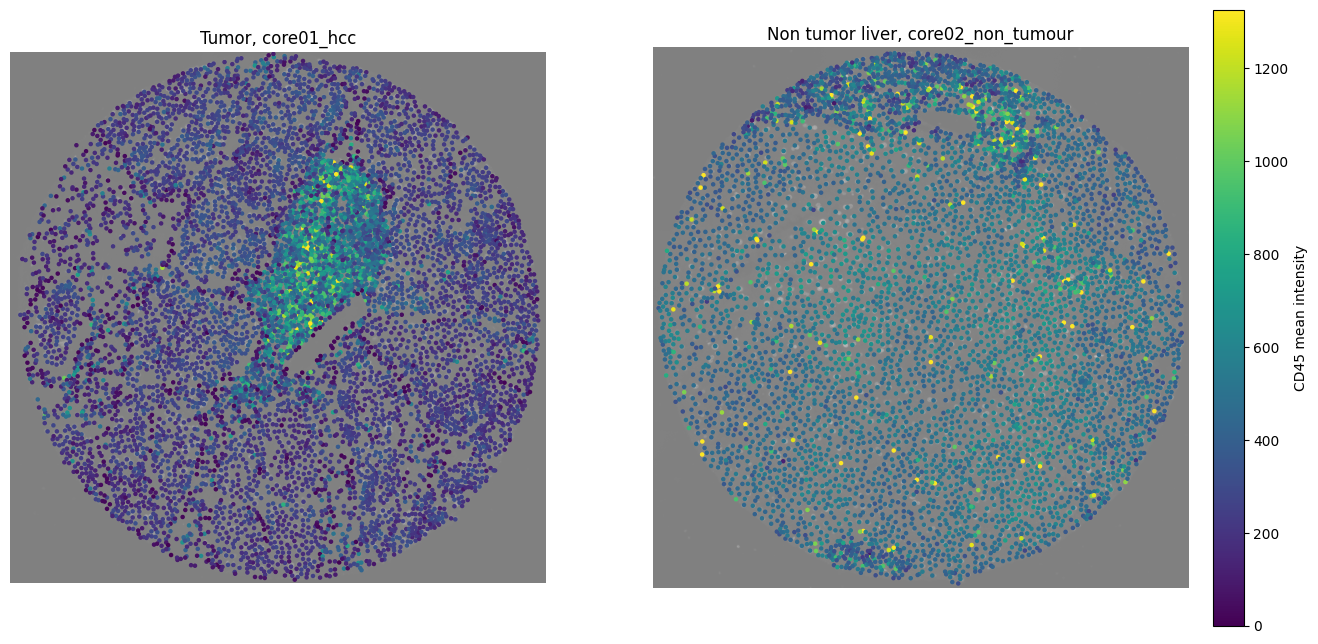

Saved slide_cd45_tumor_vs_normal.png


In [11]:
def get_dapi(loader, core_id):
    markers = loader.comet_markers[core_id]
    return loader.get_comet_channel(core_id, markers.index("DAPI"))

dapi_tumor = get_dapi(loader, tumor_id)
dapi_normal = get_dapi(loader, normal_id)

marker_col = "CD45 - TRITC_mean"
vmax = max(df_tumor[marker_col].quantile(0.99), df_normal[marker_col].quantile(0.99))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, df, dapi, title in [
    (axes[0], df_tumor, dapi_tumor, "Tumor, core01_hcc"),
    (axes[1], df_normal, dapi_normal, "Non tumor liver, core02_non_tumour"),
]:
    ax.imshow(dapi, cmap="gray", alpha=0.5)
    sc = ax.scatter(df["centroid_x"], df["centroid_y"], c=df[marker_col], cmap="viridis", s=5, vmin=0, vmax=vmax)
    ax.set_xlim(0, dapi.shape[1])
    ax.set_ylim(dapi.shape[0], 0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)

fig.colorbar(sc, ax=axes, label="CD45 mean intensity", fraction=0.03, pad=0.02)
plt.savefig(OUTPUT_DIR / "slide_cd45_tumor_vs_normal.png", dpi=200, facecolor="white", bbox_inches="tight")
plt.show()

print("Saved slide_cd45_tumor_vs_normal.png")


## A simple numeric comparison

Beyond the visual pattern, we can put an actual number on immune presence in each core. Here we use a simple, illustrative threshold, cells above the 75th percentile of CD45 across both cores combined are counted as CD45 high. This is not a rigorous cell typing method, proper cell typing usually involves clustering across many markers at once, but it is a reasonable way to get a quick, honest comparison for this video.


CD45 high threshold: 515.1
Tumor core, percent CD45 high cells: 12.0
Non tumor core, percent CD45 high cells: 44.3


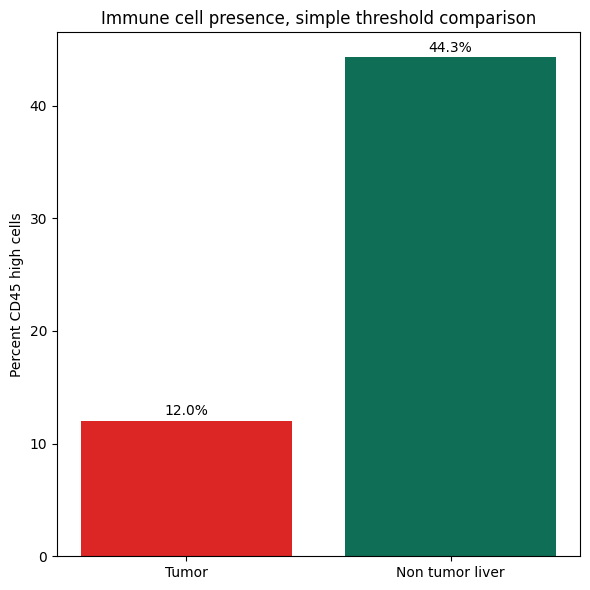

Saved slide_cd45_fraction_comparison.png


In [12]:
combined_cd45 = pd.concat([df_tumor[marker_col], df_normal[marker_col]])
threshold = combined_cd45.quantile(0.75)

frac_tumor = (df_tumor[marker_col] > threshold).mean() * 100
frac_normal = (df_normal[marker_col] > threshold).mean() * 100

print(f"CD45 high threshold: {threshold:.1f}")
print(f"Tumor core, percent CD45 high cells: {frac_tumor:.1f}")
print(f"Non tumor core, percent CD45 high cells: {frac_normal:.1f}")

fig, ax = plt.subplots(figsize=(6, 6))
bars = ax.bar(["Tumor", "Non tumor liver"], [frac_tumor, frac_normal], color=["#DC2626", "#0F6E56"])
ax.set_ylabel("Percent CD45 high cells")
ax.set_title("Immune cell presence, simple threshold comparison")
for bar, value in zip(bars, [frac_tumor, frac_normal]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_cd45_fraction_comparison.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_cd45_fraction_comparison.png")


## Summary

Across this episode we repeated the full pipeline built over the series, registration, segmentation, quantification, on a second, biologically different core, and compared it directly against the first. The comparison shows a real, visible difference in immune cell presence between the tumor and non tumor liver tissue, consistent with what we would expect biologically, without needing to hand annotate a single cell.

This closes out the introductory arc of the Multimodal Spatial Biology series. The same tools, loading, registration, segmentation, and quantification, apply just as well to the tonsil and hepatocellular adenoma cores in this dataset, which are natural candidates for future episodes if we continue this series.
